# Day 101 — MLP Notation

In this notebook we will:
1. Define the **notation** of a Multi-Layer Perceptron (layers, weights, biases, pre-activations, activations)
2. Count **parameters** for any architecture
3. Compute a forward pass **node by node** and then **vectorized**, and show they match
4. Verify a **hand-calculated** numerical example
5. Process a **batch** of samples and track the **shapes**
6. Compare the two common **weight-matrix conventions**
7. Draw the network diagram with labels
8. Cross-check our notation against **scikit-learn's** stored weights

## Notation used in these notes

| Symbol | Meaning |
|---|---|
| `L` | Number of layers **excluding** the input layer (hidden layers + output layer) |
| `n_l` | Number of nodes in layer `l` (`n_0` = number of input features) |
| `a^0 = x` | Input vector (layer 0) |
| `W^l` | Weight matrix of layer `l`, shape `(n_{l-1}, n_l)` |
| `w^l_{ij}` | Weight from node `i` of layer `l-1` **to** node `j` of layer `l` |
| `b^l` | Bias vector of layer `l`, shape `(n_l,)` |
| `z^l` | Pre-activation of layer `l`: `z^l = a^{l-1} W^l + b^l` |
| `f^l` | Activation function of layer `l` |
| `a^l` | Output (activation) of layer `l`: `a^l = f^l(z^l)` |
| `ŷ = a^L` | Network output |

Node level: `z^l_j = Σ_i  a^{l-1}_i · w^l_{ij} + b^l_j` and `a^l_j = f(z^l_j)`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.neural_network import MLPClassifier

np.random.seed(42)

def sigmoid(z): return 1 / (1 + np.exp(-z))
def relu(z):    return np.maximum(0, z)

## 1. An example architecture: 4 → 3 → 2 → 1

- Input layer: 4 features (`n_0 = 4`)
- Hidden layer 1: 3 nodes (`n_1 = 3`)
- Hidden layer 2: 2 nodes (`n_2 = 2`)
- Output layer: 1 node (`n_3 = 1`)

So `L = 3` (the input layer is **not** counted).

In [2]:
layer_sizes = [4, 3, 2, 1]               # n_0, n_1, n_2, n_3
L = len(layer_sizes) - 1                  # number of layers excluding the input layer
print("L (layers excluding input) =", L)
print("Hidden layers              =", L - 1)

# Parameters: W^l has shape (n_{l-1}, n_l), b^l has shape (n_l,)
params = {}
for l in range(1, L + 1):
    params[f"W{l}"] = np.random.randn(layer_sizes[l - 1], layer_sizes[l]) * 0.5
    params[f"b{l}"] = np.zeros(layer_sizes[l])

total = 0
print(f"\n{'Layer':>6} | {'W shape':>9} | {'b shape':>8} | {'weights':>7} | {'biases':>6} | {'params':>6}")
for l in range(1, L + 1):
    W, b = params[f"W{l}"], params[f"b{l}"]
    print(f"{l:6d} | {str(W.shape):>9} | {str(b.shape):>8} | {W.size:7d} | {b.size:6d} | {W.size + b.size:6d}")
    total += W.size + b.size
print("\nTotal trainable parameters:", total)
print("Formula check: sum over l of (n_{l-1} * n_l + n_l) =",
      sum(layer_sizes[l-1] * layer_sizes[l] + layer_sizes[l] for l in range(1, L + 1)))

L (layers excluding input) = 3
Hidden layers              = 2

 Layer |   W shape |  b shape | weights | biases | params
     1 |    (4, 3) |     (3,) |      12 |      3 |     15
     2 |    (3, 2) |     (2,) |       6 |      2 |      8
     3 |    (2, 1) |     (1,) |       2 |      1 |      3

Total trainable parameters: 26
Formula check: sum over l of (n_{l-1} * n_l + n_l) = 26


## 2. Forward pass, node by node (using the index notation)

`z^l_j = Σ_i a^{l-1}_i · w^l_{ij} + b^l_j`,  `a^l_j = f(z^l_j)`

In [3]:
def forward_nodewise(x, params, L, hidden_act=np.tanh, out_act=sigmoid):
    a_prev = list(x)                                         # a^0
    for l in range(1, L + 1):
        W, b = params[f"W{l}"], params[f"b{l}"]
        n_prev, n_curr = W.shape
        f = out_act if l == L else hidden_act
        a_curr = []
        for j in range(n_curr):                              # each node j in layer l
            z_j = b[j]
            for i in range(n_prev):                          # each node i in layer l-1
                z_j += a_prev[i] * W[i, j]                   # w^l_{ij} = W[i, j]
            a_curr.append(f(np.array(z_j)))
        a_prev = a_curr
    return np.array(a_prev)

x = np.array([0.5, -1.0, 2.0, 0.1])
print("Node-wise output (tanh hidden units, sigmoid output):", forward_nodewise(x, params, L))

Node-wise output (tanh hidden units, sigmoid output): [0.66529858]


## 3. Forward pass, vectorized

`z^l = a^{l-1} W^l + b^l`,  `a^l = f(z^l)`  (with samples as **rows**)

In [4]:
def forward(X, params, L, hidden_act=np.tanh, out_act=sigmoid, return_cache=False):
    A = X
    cache = {"a0": X}
    for l in range(1, L + 1):
        Z = A @ params[f"W{l}"] + params[f"b{l}"]
        A = out_act(Z) if l == L else hidden_act(Z)
        cache[f"z{l}"], cache[f"a{l}"] = Z, A
    return (A, cache) if return_cache else A

out_vec = forward(x.reshape(1, -1), params, L)
print("Vectorized output:", out_vec.ravel())
print("Same as node-wise?", np.allclose(out_vec.ravel(), forward_nodewise(x, params, L)))

Vectorized output: [0.66529858]
Same as node-wise? True


## 4. A hand-calculated example (2 → 2 → 1)

Inputs `x = [1, 2]`. Hidden layer: sigmoid. Output layer: sigmoid.

```
W1 = [[0.1, 0.3],     b1 = [0.1, 0.1]
      [0.2, 0.4]]
W2 = [[0.5],          b2 = [0.2]
      [0.6]]
```

Hand calculation of the first hidden node: `z^1_1 = 1·0.1 + 2·0.2 + 0.1 = 0.6`.

In [5]:
x_small = np.array([[1.0, 2.0]])
W1 = np.array([[0.1, 0.3], [0.2, 0.4]]); b1 = np.array([0.1, 0.1])
W2 = np.array([[0.5], [0.6]]);           b2 = np.array([0.2])

z1 = x_small @ W1 + b1
a1 = sigmoid(z1)
z2 = a1 @ W2 + b2
a2 = sigmoid(z2)

print("z^1 =", z1.ravel(), "(first node by hand: 0.6)")
print("a^1 =", a1.ravel().round(4))
print("z^2 =", z2.ravel().round(4))
print("y_hat = a^2 =", a2.ravel().round(4))

# manual check of z^2 by hand
manual_z2 = a1[0, 0] * 0.5 + a1[0, 1] * 0.6 + 0.2
print("Manual z^2:", round(manual_z2, 4))

z^1 = [0.6 1.2] (first node by hand: 0.6)
a^1 = [0.6457 0.7685]
z^2 = [0.9839]
y_hat = a^2 = [0.7279]
Manual z^2: 0.9839


## 5. Batches: tracking shapes

With `m` samples stacked as rows, `X` has shape `(m, n_0)` and every layer works on the whole batch at once.

In [6]:
m = 5
X_batch = np.random.randn(m, layer_sizes[0])
y_hat, cache = forward(X_batch, params, L, return_cache=True)

print(f"{'Quantity':>10} | {'shape':>10} | meaning")
print(f"{'a0 = X':>10} | {str(cache['a0'].shape):>10} | (m, n_0)")
for l in range(1, L + 1):
    print(f"{'z' + str(l):>10} | {str(cache['z' + str(l)].shape):>10} | (m, n_{l})")
    print(f"{'a' + str(l):>10} | {str(cache['a' + str(l)].shape):>10} | (m, n_{l})")
print("\nPredictions for the batch:", y_hat.ravel().round(3))

  Quantity |      shape | meaning
    a0 = X |     (5, 4) | (m, n_0)
        z1 |     (5, 3) | (m, n_1)
        a1 |     (5, 3) | (m, n_1)
        z2 |     (5, 2) | (m, n_2)
        a2 |     (5, 2) | (m, n_2)
        z3 |     (5, 1) | (m, n_3)
        a3 |     (5, 1) | (m, n_3)

Predictions for the batch: [0.532 0.353 0.373 0.518 0.371]


We store `z^l` and `a^l` for each layer (the **cache**). The backward pass (backpropagation) will need them.

## 6. Two weight-matrix conventions

Different books and libraries use different layouts. They describe the same network.

| | Convention A (these notes) | Convention B |
|---|---|---|
| Data layout | samples as **rows** | samples as **columns** |
| `W^l` shape | `(n_{l-1}, n_l)` | `(n_l, n_{l-1})` |
| Forward formula | `Z = A_prev @ W + b` | `Z = W @ A_prev + b` |
| Used by | scikit-learn `coefs_`, Keras `Dense` | Many textbooks and courses, PyTorch `nn.Linear.weight` |

They are related by a transpose: `W_B = W_A.T`.

In [7]:
W_A = params["W1"]                  # shape (4, 3)
W_B = W_A.T                         # shape (3, 4)
b1 = params["b1"]

x_row = x.reshape(1, -1)            # (1, 4)
x_col = x.reshape(-1, 1)            # (4, 1)

z_A = x_row @ W_A + b1              # (1, 3)
z_B = W_B @ x_col + b1.reshape(-1, 1)   # (3, 1)

print("Convention A shape:", W_A.shape, "-> z =", z_A.ravel().round(4))
print("Convention B shape:", W_B.shape, "-> z =", z_B.ravel().round(4))
print("Identical result:", np.allclose(z_A.ravel(), z_B.ravel()))

Convention A shape: (4, 3) -> z = [ 0.969   0.8268 -0.2138]
Convention B shape: (3, 4) -> z = [ 0.969   0.8268 -0.2138]
Identical result: True


## 7. Draw the network with its notation

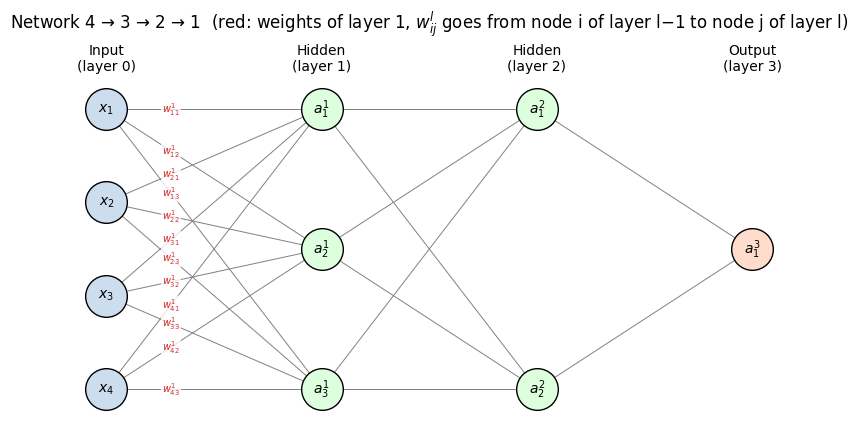

In [8]:
def draw_network(layer_sizes, show_weight_labels_layer=1):
    fig, ax = plt.subplots(figsize=(10, 5))
    xs = np.linspace(0, 1, len(layer_sizes))
    pos = {}
    for l, n in enumerate(layer_sizes):
        ys = np.linspace(0.9, 0.1, n) if n > 1 else [0.5]
        for i, y_ in enumerate(ys):
            pos[(l, i)] = (xs[l], y_)

    for l in range(1, len(layer_sizes)):
        for i in range(layer_sizes[l - 1]):
            for j in range(layer_sizes[l]):
                (x0, y0), (x1, y1) = pos[(l - 1, i)], pos[(l, j)]
                ax.plot([x0, x1], [y0, y1], color="gray", lw=0.7, zorder=1)
                if l == show_weight_labels_layer:
                    t = 0.3
                    ax.text(x0 + (x1 - x0) * t, y0 + (y1 - y0) * t, f"$w^{{{l}}}_{{{i+1}{j+1}}}$",
                            fontsize=7, color="tab:red", ha="center", va="center", zorder=3,
                            bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.8))

    for (l, i), (px, py) in pos.items():
        color = "#cde" if l == 0 else ("#fdc" if l == len(layer_sizes) - 1 else "#dfd")
        ax.scatter(px, py, s=900, color=color, edgecolor="k", zorder=2)
        label = f"$x_{i+1}$" if l == 0 else f"$a^{{{l}}}_{i+1}$"
        ax.text(px, py, label, ha="center", va="center", fontsize=10, zorder=4)

    names = ["Input\n(layer 0)"] + [f"Hidden\n(layer {l})" for l in range(1, len(layer_sizes) - 1)] + [f"Output\n(layer {len(layer_sizes)-1})"]
    for xv, nm in zip(xs, names):
        ax.text(xv, 1.0, nm, ha="center", va="bottom", fontsize=10)
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(0, 1.1); ax.axis("off")
    ax.set_title("Network 4 → 3 → 2 → 1  (red: weights of layer 1, $w^l_{ij}$ goes from node i of layer l−1 to node j of layer l)")
    plt.show()

draw_network(layer_sizes)

## 8. Cross-check with scikit-learn

scikit-learn's `MLPClassifier` stores weights in `coefs_[l]` with shape `(n_{l-1}, n_l)` (Convention A) and biases in `intercepts_[l]`.
We recompute its predictions with our own forward function.

In [9]:
X, y = make_moons(n_samples=300, noise=0.2, random_state=0)
clf = MLPClassifier(hidden_layer_sizes=(6, 4), activation="relu", max_iter=2000, random_state=0).fit(X, y)

sk_params = {}
for l, (W, b) in enumerate(zip(clf.coefs_, clf.intercepts_), start=1):
    sk_params[f"W{l}"], sk_params[f"b{l}"] = W, b
    print(f"Layer {l}: W shape = {W.shape}, b shape = {b.shape}")

L_sk = len(clf.coefs_)
my_proba = forward(X, sk_params, L_sk, hidden_act=relu, out_act=sigmoid).ravel()
sk_proba = clf.predict_proba(X)[:, 1]
print("\nMax difference between our forward pass and scikit-learn:", np.abs(my_proba - sk_proba).max())
print("Same predicted classes:", np.array_equal((my_proba >= 0.5).astype(int), clf.predict(X)))

Layer 1: W shape = (2, 6), b shape = (6,)
Layer 2: W shape = (6, 4), b shape = (4,)
Layer 3: W shape = (4, 1), b shape = (1,)

Max difference between our forward pass and scikit-learn: 1.1102230246251565e-16
Same predicted classes: True


## Summary

| Item | Rule |
|---|---|
| Layers | `L` counts hidden + output layers, the input layer is layer 0 |
| Weights | `w^l_{ij}`: node `i` of layer `l-1` → node `j` of layer `l` |
| Matrix shapes | `W^l`: `(n_{l-1}, n_l)`, `b^l`: `(n_l,)` |
| Forward step | `z^l = a^{l-1} W^l + b^l`, then `a^l = f(z^l)` |
| Parameters | `Σ (n_{l-1}·n_l + n_l)` |
| Batch | `X`: `(m, n_0)`, every `z^l`, `a^l`: `(m, n_l)` |

## Practice exercises

1. Count the parameters of a `10 → 8 → 8 → 4 → 1` network by hand, then verify in code.
2. Switch the hidden activation from `tanh` to `relu` in `forward`. With these random weights, what happens to the output when every hidden pre-activation is negative?
3. Write `forward` using Convention B (samples as columns) and prove it matches Convention A.
4. Add a **softmax** output layer for a 3-class problem and check that each row of outputs sums to 1.
5. Print a Keras-style `summary()` table (layer, output shape, parameters) for any `layer_sizes` list.